# 03 — OpenCV Color Spaces & Channels

This notebook focuses on practical color-space handling in OpenCV: BGR, RGB, Grayscale, HSV, LAB, YCrCb, channels, and color masking.

**Goal:** understand how to convert, inspect, manipulate, and use color information in computer vision.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")

if image is None:
    raise FileNotFoundError("cat.jpg not found")

print("Shape:", image.shape)

Shape: (350, 525, 3)


## 1. BGR vs RGB

OpenCV stores a normal color image as **BGR**, while Matplotlib expects **RGB**.

Always convert before displaying an OpenCV BGR image with Matplotlib.

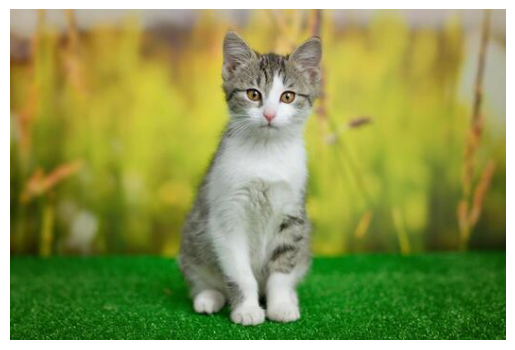

In [3]:
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(rgb)
plt.axis("off")
plt.show()

## 2. `cv2.cvtColor()`

**Syntax:** `cv2.cvtColor(src, code)`

- `src` → input image
- `code` → conversion type
- **Return:** converted image

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

print("BGR:", image.shape)
print("Gray:", gray.shape)
print("HSV:", hsv.shape)

BGR: (350, 525, 3)
Gray: (350, 525)
HSV: (350, 525, 3)


## 3. Grayscale

A grayscale image has one intensity value per pixel, so its shape becomes `(H, W)` instead of `(H, W, 3)`.

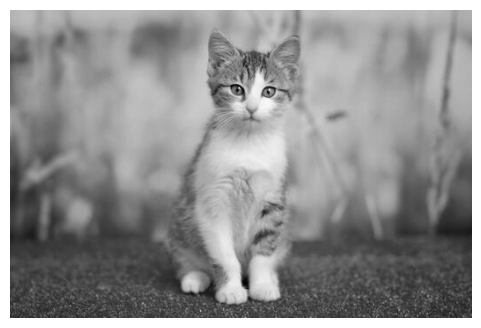

In [5]:
plt.figure(figsize=(6,4))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

## 4. Grayscale conversion — the math

Grayscale is **not** normally calculated as `(R + G + B) / 3`.

For 8-bit images, OpenCV uses approximately:

\[Y = 0.114B + 0.587G + 0.299R\]

Green receives the largest weight because human vision is more sensitive to green intensity.

In [6]:
b, g, r = cv2.split(image)

gray_manual = (
    0.114 * b.astype(np.float32) +
    0.587 * g.astype(np.float32) +
    0.299 * r.astype(np.float32)
).astype(np.uint8)

print("OpenCV vs manual maximum difference:",
      np.max(cv2.absdiff(gray, gray_manual)))

OpenCV vs manual maximum difference: 1


## 5. Splitting channels

`cv2.split()` separates an image into individual channels.

For a BGR image:

`B, G, R = cv2.split(image)`

B channel: (350, 525)
G channel: (350, 525)
R channel: (350, 525)


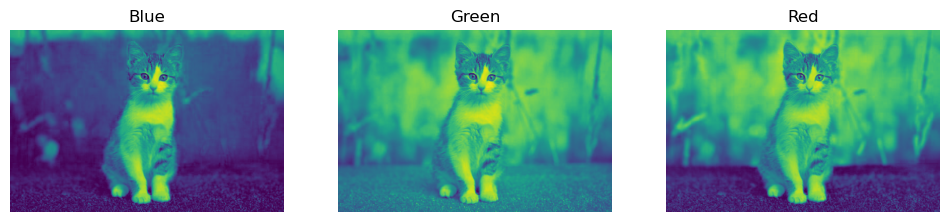

In [7]:
B, G, R = cv2.split(image)

print("B channel:", B.shape)
print("G channel:", G.shape)
print("R channel:", R.shape)

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for ax, channel, title in zip(axes, [B, G, R], ["Blue", "Green", "Red"]):
    ax.imshow(channel)
    # ax.imshow(channel, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.show()

## 6. Merging channels

`cv2.merge([B, G, R])` combines separate single-channel arrays into a color image.

The channel order must match the format you want to create.

In [8]:
merged = cv2.merge([B, G, R])

print("Same shape:", merged.shape)
print("Same image:", np.array_equal(image, merged))

Same shape: (350, 525, 3)
Same image: True


## 7. Channel manipulation

Changing one channel changes the corresponding color component of the image.

This is useful for understanding how color information is stored.

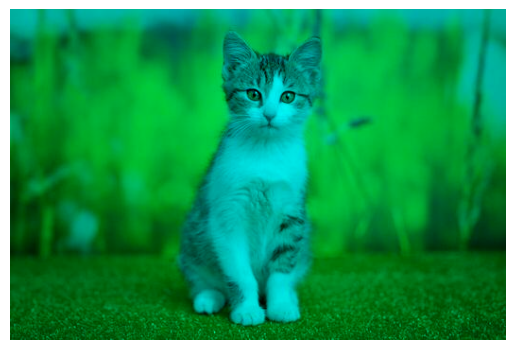

In [9]:
modified = image.copy()
modified[:, :, 2] = 0   # remove Red channel

plt.imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 8. HSV color space

HSV separates color into:

- **H — Hue:** type of color
- **S — Saturation:** color intensity/purity
- **V — Value:** brightness

HSV is commonly useful for color-based segmentation.

### OpenCV HSV ranges

For an 8-bit HSV image:

- `H`: `0–179`
- `S`: `0–255`
- `V`: `0–255`

Hue uses `0–179` in OpenCV instead of the usual `0–360°` representation.

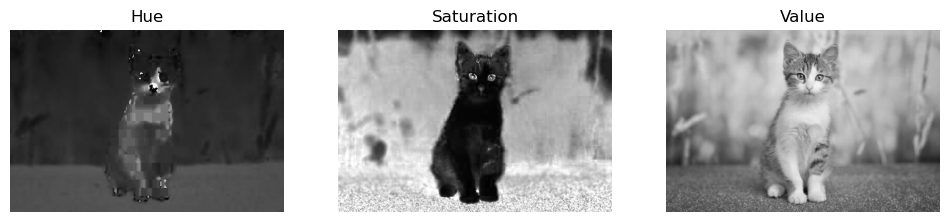

In [18]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv)

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for ax, channel, title in zip(axes, [H, S, V], ["Hue", "Saturation", "Value"]):
    ax.imshow(channel, cmap="gray")
    # ax.imshow(channel)
    ax.set_title(title)
    ax.axis("off")

plt.show()

## 9. HSV math

For normalized RGB values where $R, G, B \in [0, 1]$:

$$V = \max(R, G, B)$$

$$S = \begin{cases} 
0, & V = 0 \\ 
\frac{V - \min(R, G, B)}{V}, & V \neq 0 
\end{cases}$$

Let $\Delta = V - \min(R, G, B)$. Hue ($H$) is defined as:

$$H = \begin{cases} 
0^\circ, & \Delta = 0 \\ 
60^\circ \times \left( \frac{G - B}{\Delta} \bmod 6 \right), & V = R \\ 
60^\circ \times \left( \frac{B - R}{\Delta} + 2 \right), & V = G \\ 
60^\circ \times \left( \frac{R - G}{\Delta} + 4 \right), & V = B 
\end{cases}$$

HSV separates **what the color is** from **how bright it is**, which makes color thresholding easier.

## 10. HSV color masking

`cv2.inRange()` creates a binary mask where pixels inside the specified range become `255`.

**Syntax:** `cv2.inRange(src, lowerb, upperb)`

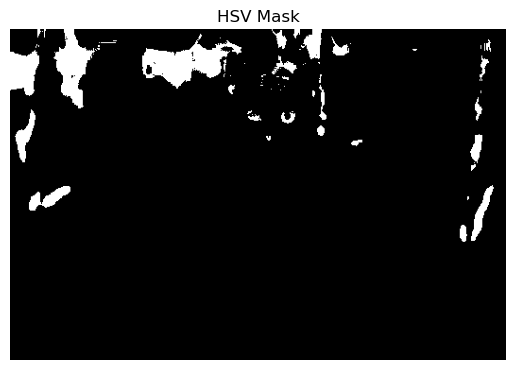

In [11]:
# Example range — adjust these values for the object in your image
lower = np.array([0, 80, 50])
upper = np.array([20, 255, 255])

mask = cv2.inRange(hsv, lower, upper)

plt.imshow(mask, cmap="gray")
plt.title("HSV Mask")
plt.axis("off")
plt.show()

## 11. Apply a mask

A mask can keep selected pixels while removing everything else.

`cv2.bitwise_and()` applies the binary mask to the source image.

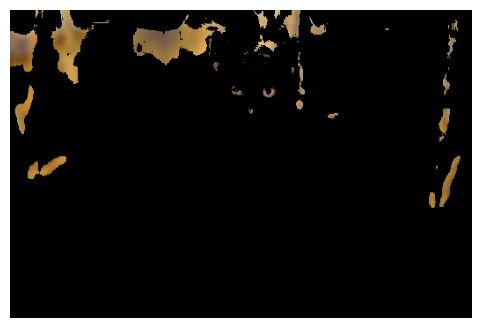

In [12]:
result = cv2.bitwise_and(image, image, mask=mask)

plt.figure(figsize=(6,4))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 12. LAB color space

LAB separates lightness from color information:

- `L` → lightness
- `a` → green ↔ red
- `b` → blue ↔ yellow

It is useful when color comparison should be less dependent on brightness.

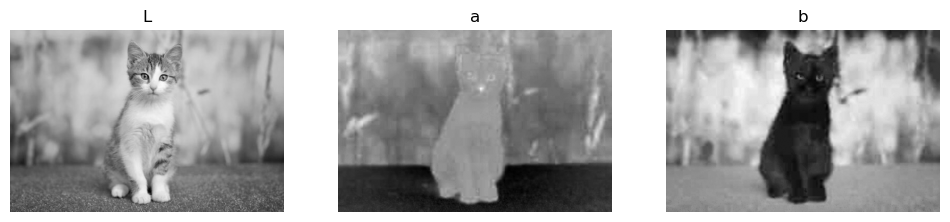

In [13]:
lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
L, A, Bb = cv2.split(lab)

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for ax, channel, title in zip(axes, [L, A, Bb], ["L", "a", "b"]):
    ax.imshow(channel, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.show()

## 13. YCrCb color space

YCrCb separates brightness from chrominance:

- `Y` → brightness
- `Cr` → red-difference
- `Cb` → blue-difference

It is widely used in image/video processing and compression.

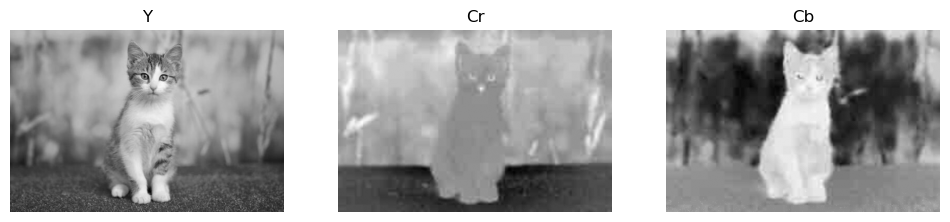

In [14]:
ycrcb = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)
Y, Cr, Cb = cv2.split(ycrcb)

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for ax, channel, title in zip(axes, [Y, Cr, Cb], ["Y", "Cr", "Cb"]):
    ax.imshow(channel, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.show()

## 14. Common color conversions

| Conversion | OpenCV code |
|---|---|
| BGR → RGB | `cv2.COLOR_BGR2RGB` |
| BGR → Gray | `cv2.COLOR_BGR2GRAY` |
| BGR → HSV | `cv2.COLOR_BGR2HSV` |
| BGR → LAB | `cv2.COLOR_BGR2LAB` |
| BGR → YCrCb | `cv2.COLOR_BGR2YCrCb` |
| RGB → BGR | `cv2.COLOR_RGB2BGR` |
| HSV → BGR | `cv2.COLOR_HSV2BGR` |
| Gray → BGR | `cv2.COLOR_GRAY2BGR` |

## 15. Channel ranges and shapes

For an 8-bit image, a normal channel usually contains values from `0–255`.

A 3-channel image has shape `(H, W, 3)`; each individual channel has shape `(H, W)`.

In [15]:
print("BGR dtype:", image.dtype)
print("BGR min/max:", image.min(), image.max())

print("Gray dtype:", gray.dtype)
print("Gray min/max:", gray.min(), gray.max())

print("HSV H:", H.min(), H.max())
print("HSV S:", S.min(), S.max())
print("HSV V:", V.min(), V.max())

BGR dtype: uint8
BGR min/max: 0 255
Gray dtype: uint8
Gray min/max: 0 249
HSV H: 0 179
HSV S: 0 255
HSV V: 0 255


## 16. Practical example — isolate a color

The typical workflow is:

**BGR → HSV → define range → create mask → apply mask**

This pattern appears frequently in object/color segmentation tasks.

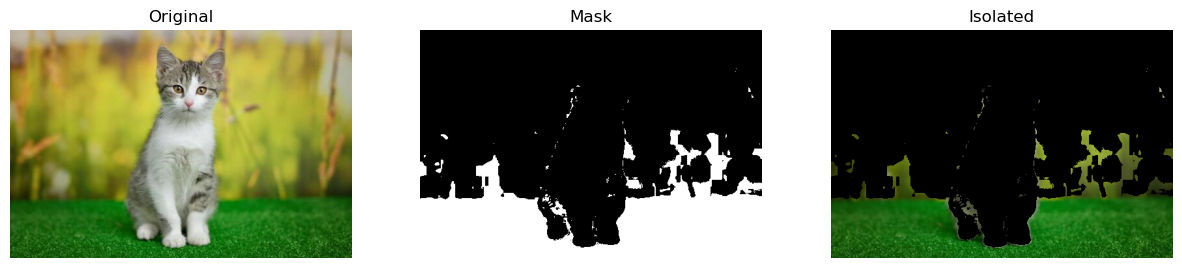

In [16]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

lower = np.array([35, 60, 40])
upper = np.array([85, 255, 255])

mask = cv2.inRange(hsv, lower, upper)
isolated = cv2.bitwise_and(image, image, mask=mask)

fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Mask")
axes[2].imshow(cv2.cvtColor(isolated, cv2.COLOR_BGR2RGB))
axes[2].set_title("Isolated")
for ax in axes:
    ax.axis("off")
plt.show()

## 17. Important notes

- OpenCV images are **BGR** by default.
- Matplotlib displays images as **RGB**.
- Grayscale has one channel.
- `split()` separates channels; `merge()` combines them.
- HSV is especially useful for color thresholding.
- `inRange()` produces a binary mask.
- Always inspect the actual image before choosing HSV thresholds.